# Process one Station

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from hydro.duration_curve import DurationCurveReporter
from hydro.station import Station
from utils.sql_connector import SqlConnector

if "conn" not in globals():
    conn = SqlConnector()

To sign in, use a web browser to open the page https://login.microsoft.com/device and enter the code AE8G75S4K to authenticate.


## Generate duration curve

In [35]:
STATION = 14558000
# THRESHOLDS = None

THRESHOLDS: dict[str, float] = {
    # "Cota de Alerta (SGB)": 800,
    # "Cota de Inundação (SGB)": 850,
    "Permanência 95%": 439,
}


RESULTS_DIR = Path("/data/CN3S/duration_curves")

station_dir = RESULTS_DIR / str(STATION)

station = Station(STATION, connector=conn)
print(f"station name: {station.name}")

if station_dir.exists():
    print(f"Loading duration curve from saved data in {station_dir}")
    duration_curve = DurationCurveReporter.from_saved(station_dir, station)
    station.load_series()

else:
    print(f"Creating new duration curve for station {station.name}")
    duration_curve = DurationCurveReporter(station, thresholds=THRESHOLDS)
    duration_curve.create_duration_curve(
        series_type="cota",
        source=None,
        method="from_discharge",
        period=slice(None, None),
    )

    duration_curve.save_results(RESULTS_DIR)

print(f"Duration curve thresholds: {duration_curve.thresholds}")

duration_curve.results

station name: FAZENDA PARAÍSO
Creating new duration curve for station FAZENDA PARAÍSO
Calculating stage duration curve from discharge data...
Duration curve thresholds: {'Permanência 95%': 439}


DurationCurveResult(station=14558000, cota, hidro, HIDRO(100.0%) - Inicio:2012/11 Fim:2026/04 Anos:13.5 Falhas(%):0.0 Consist(%):82.7, cota/vazao)

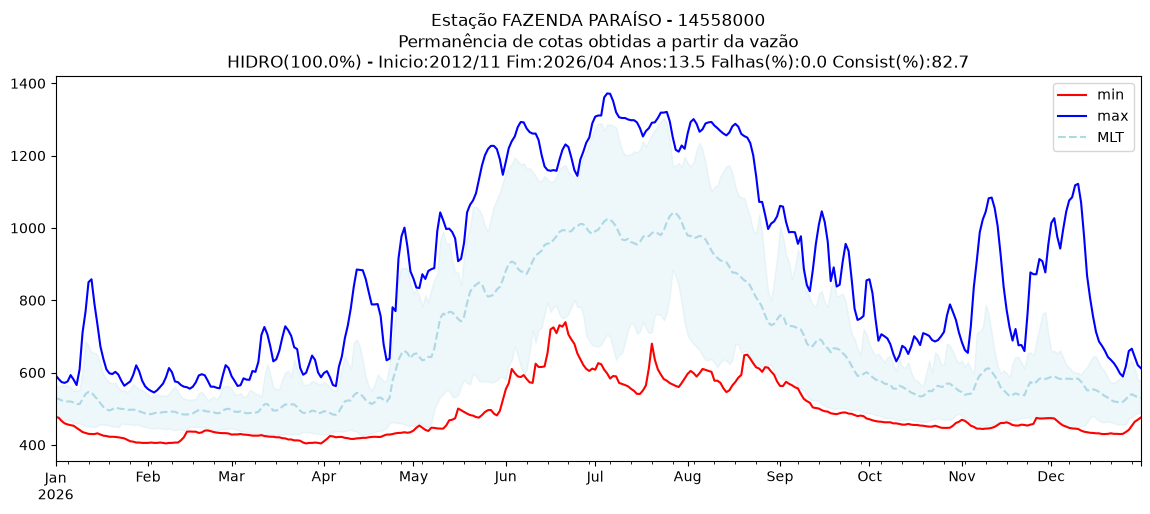

In [36]:
fig, ax = plt.subplots(figsize=(14, 5))

duration_curve.plot_duration_curve(ax)

fig.savefig(station_dir / "duration_curve.png")

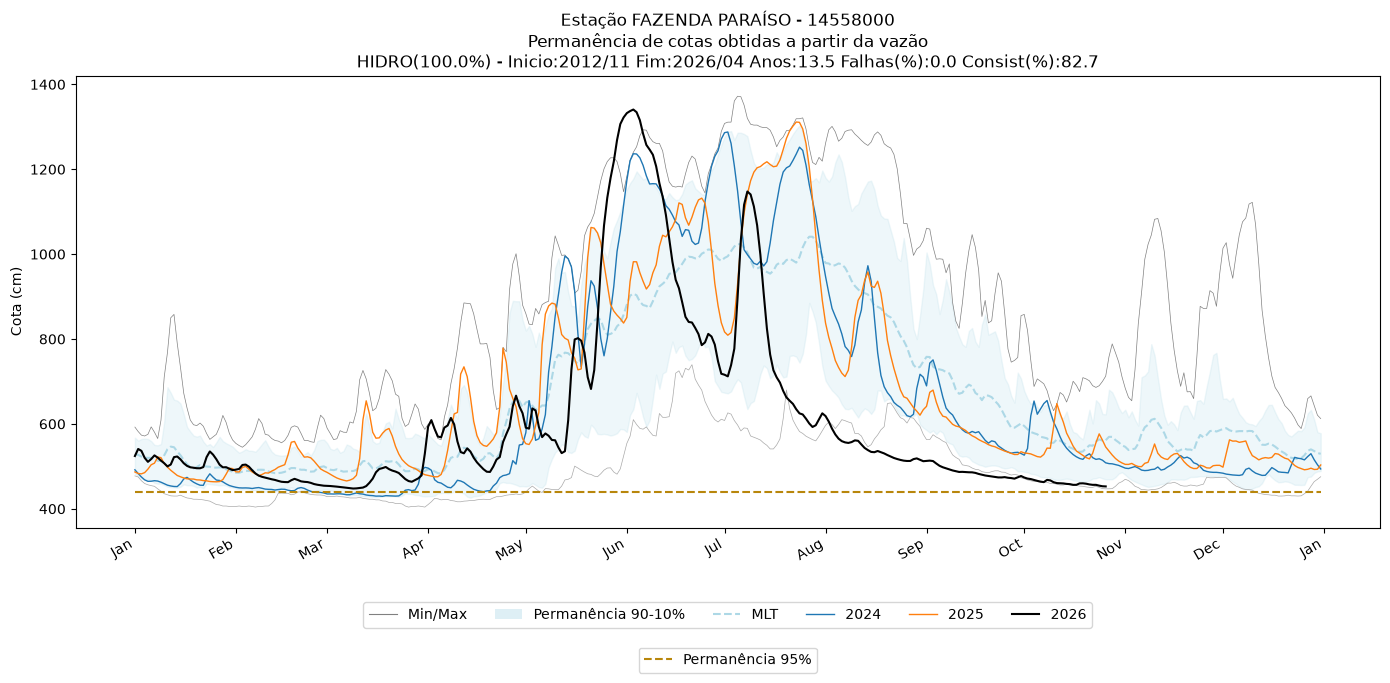

In [37]:
fig, ax = plt.subplots(figsize=(14, 7))

duration_curve.plot_annual_stage_chart(ax)

fig.savefig(station_dir / "annual_stage_chart.png")


## Load existing station

In [13]:
STATION = 14489000

# THRESHOLDS: dict[str, float] = {
#     "Cota de Alerta (SGB)": 850,
#     "Cota de Inundação (SGB)": 900,
#     "Permanência 95%": 54.7,
# }

RESULTS_DIR = Path("/data/CN3S/duration_curves")

station_dir = RESULTS_DIR / str(STATION)

In [14]:
station = Station(STATION, connector=conn)
station.name

'MARACÁ'

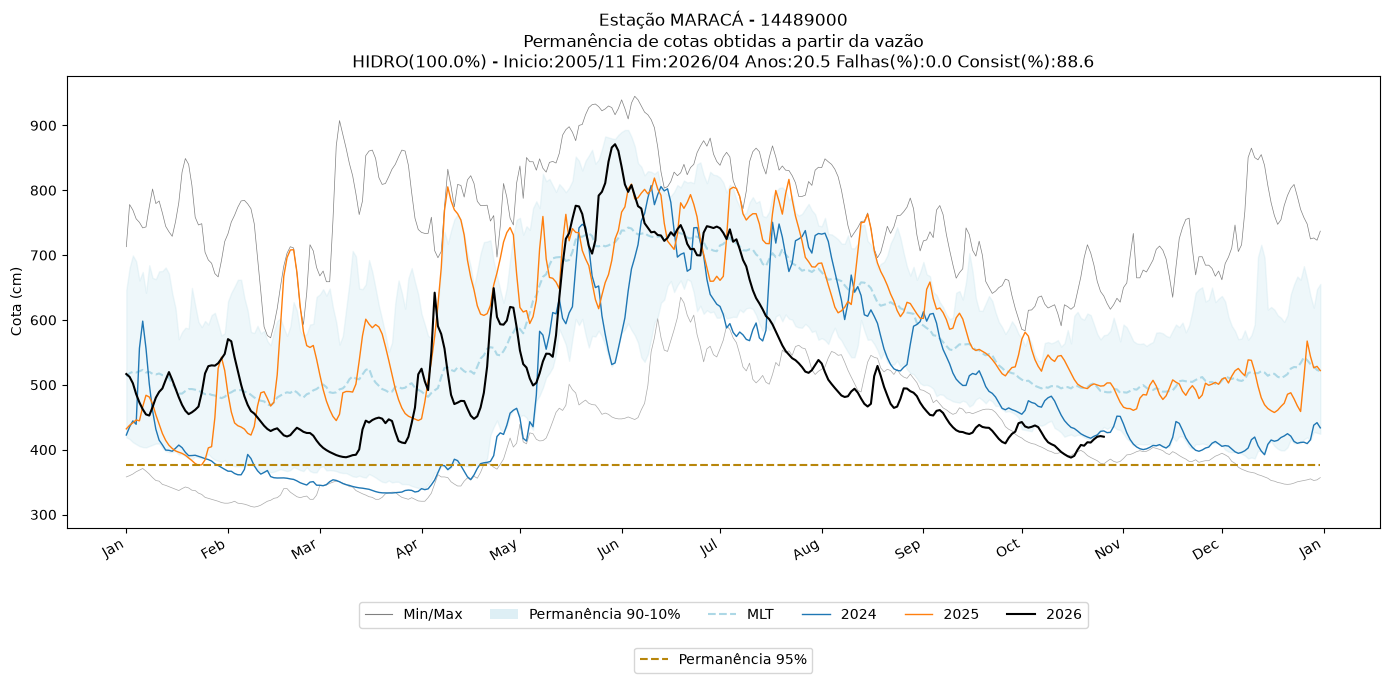

In [15]:
# Reload the saved result: same chart and thresholds, with telemetry refreshed to the last day
duration_curve = DurationCurveReporter.from_saved(station_dir, station)
station.load_series()

fig, ax = plt.subplots(figsize=(14, 7))

duration_curve.plot_annual_stage_chart(ax)

fig.savefig(station_dir / "annual_stage_chart.png")
